# 03 · Wavelet Scattering + linear SVM

固定小波散射提取图像特征，后接线性 SVM。`J=2, L=8, max_order=2` 保持固定，只选择 SVM 的正则化参数 C。

散射滤波器不使用标签、没有可学习权重，因此原始散射系数可以按图像独立计算并缓存。**标准化和 SVM 只能在当前训练分区内拟合。** 本方法没有 CNN 的 epoch-loss 曲线，记录训练／验证准确率随 C 的变化。

The linear SVM uses scikit-learn SVC(kernel="linear"), backed by LIBSVM; the implementation was chosen using training-only timing checks.

In [1]:
import os
import time
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from data_utils import ROOT, load_data, get_trial, validation_indices, output_folder, SEED
from plot_utils import save_figure, plot_training_split
from evaluation import save_json, evaluate_predictions, save_method_summary, compare_methods
from scattering_utils import scattering_features, plot_scattering

torch.set_num_threads(min(4, os.cpu_count() or 1))
device = "cpu"
C_values = [0.01, 0.1, 1.0]
data = load_data()

## 1. 提取并缓存固定特征
第一次运行计算 4,000 张图像的系数，重复运行直接加载缓存。特征提取时间单独保存，不与 SVM 拟合时间混淆。

Loaded fixed-feature cache: (4000, 3969)
Scattering feature shape: (4000, 3969)
Feature extraction seconds (zero means cached): 0.0


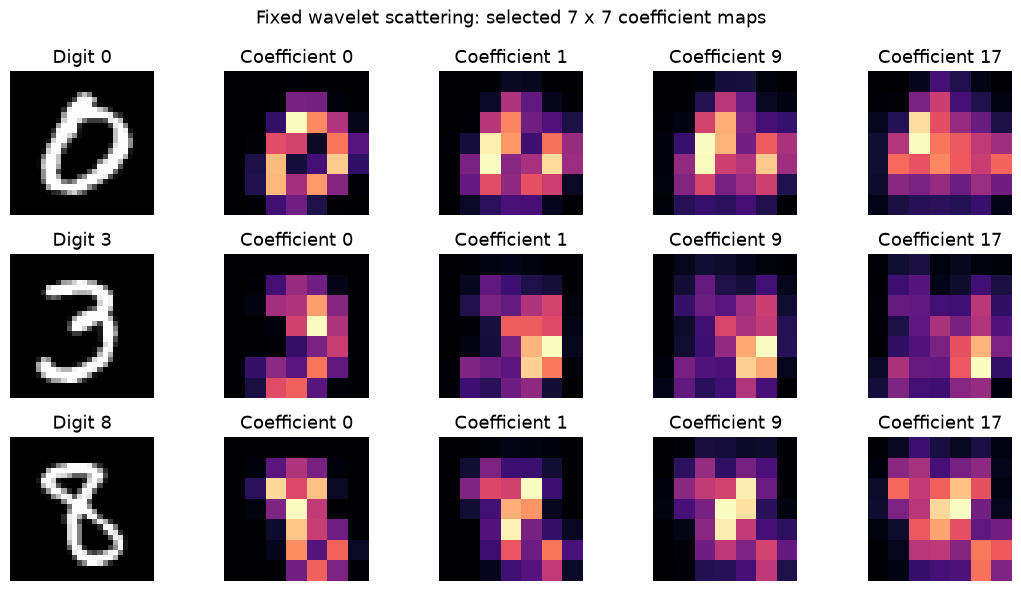

In [2]:
cache_path = ROOT / ".cache" / "scattering_j2_l8_order2.npy"
cache_used = cache_path.exists()
features, extraction_seconds = scattering_features(data["images"], cache_path, device=device)
extraction_info = {"cache_used": cache_used, "this_run_seconds": extraction_seconds,
                   "shape": list(features.shape), "J": 2, "L": 8, "max_order": 2}
save_json(extraction_info, output_folder("scattering") / "feature_extraction.json")
if not cache_used:
    save_json(extraction_info, output_folder("scattering") / "cold_feature_extraction.json")
print("Scattering feature shape:", features.shape)
print("Feature extraction seconds (zero means cached):", extraction_seconds)
train_images, train_labels, _, _ = get_trial(data, 1)
plot_scattering(train_images, train_labels, output_folder("scattering"), device=device)

## 2. 只用训练内部验证集选择 C
两个 trial 独立选择参数。每个候选 Pipeline 内部独立拟合 StandardScaler；选择后重新在全部 2,000 张训练图像上拟合。

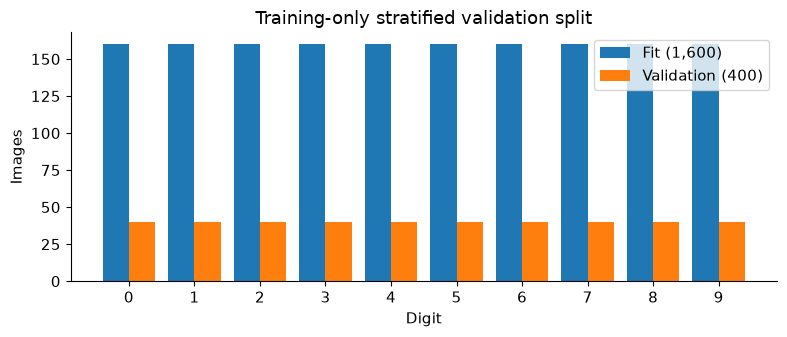

,C,train_accuracy,validation_accuracy,fit_seconds
0,0.01,1.0,0.9825,4.926043
1,0.10,1.0,0.9825,4.926011
2,1.00,1.0,0.9825,5.055818


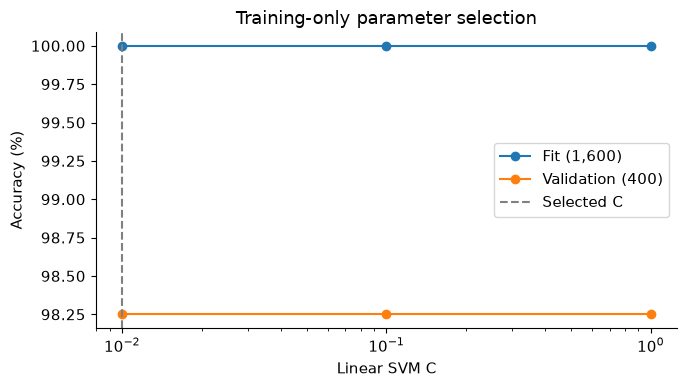

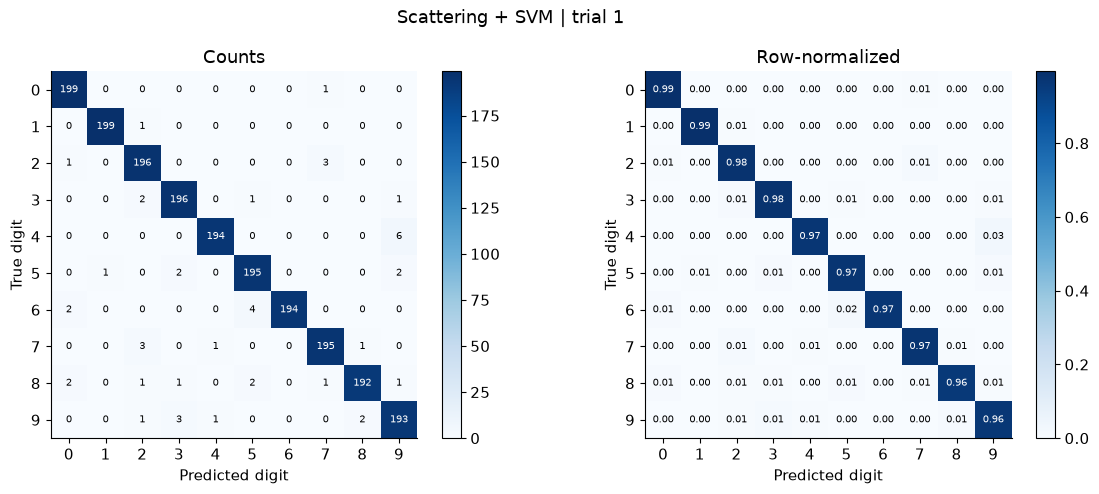

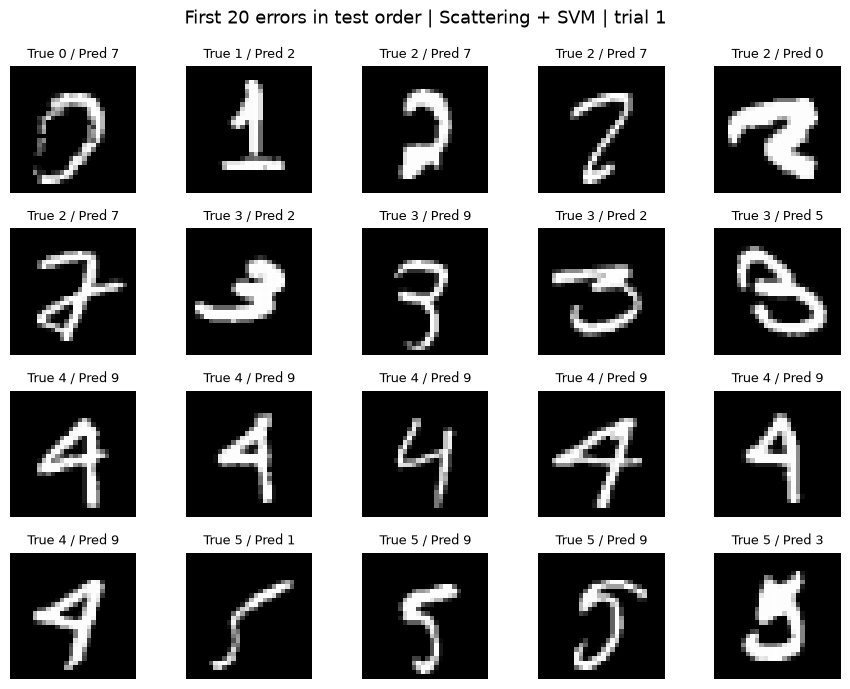

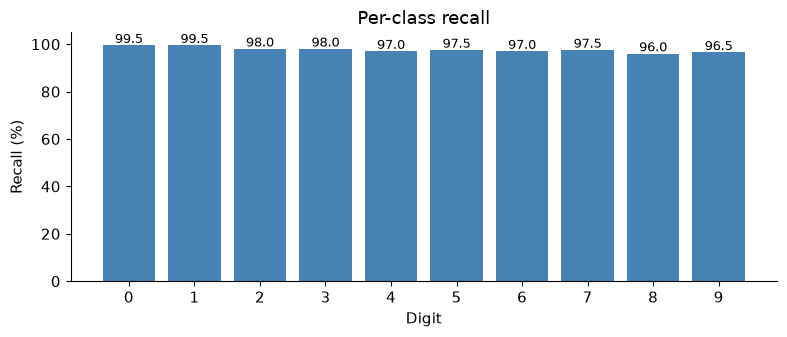

Scattering + SVM trial 1 accuracy = 0.9765


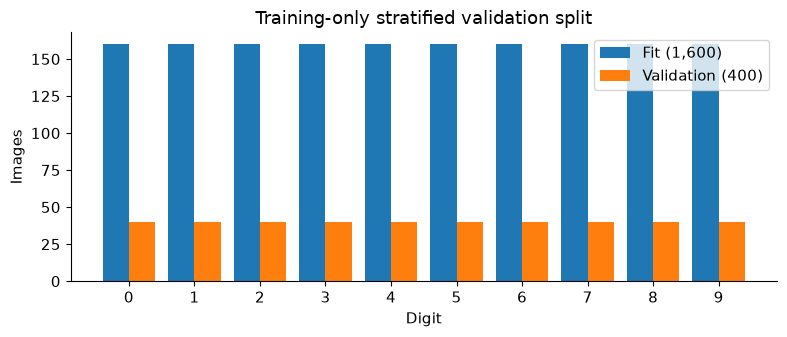

,C,train_accuracy,validation_accuracy,fit_seconds
0,0.01,1.0,0.98,5.182338
1,0.10,1.0,0.98,5.476468
2,1.00,1.0,0.98,5.080586


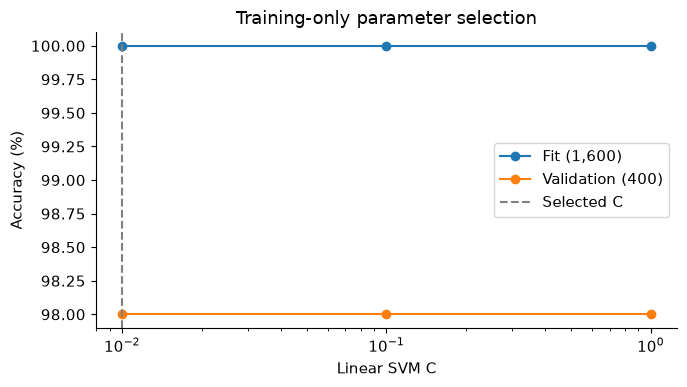

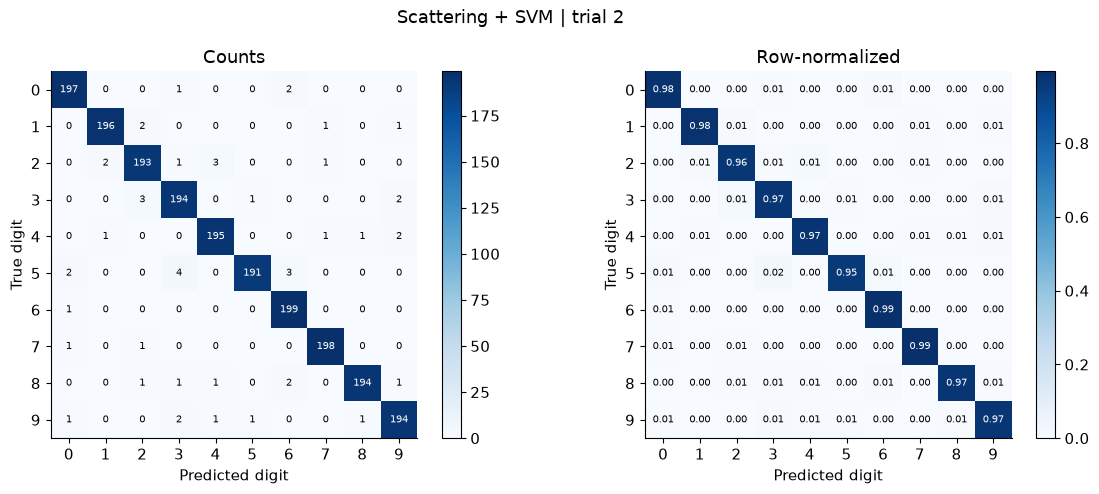

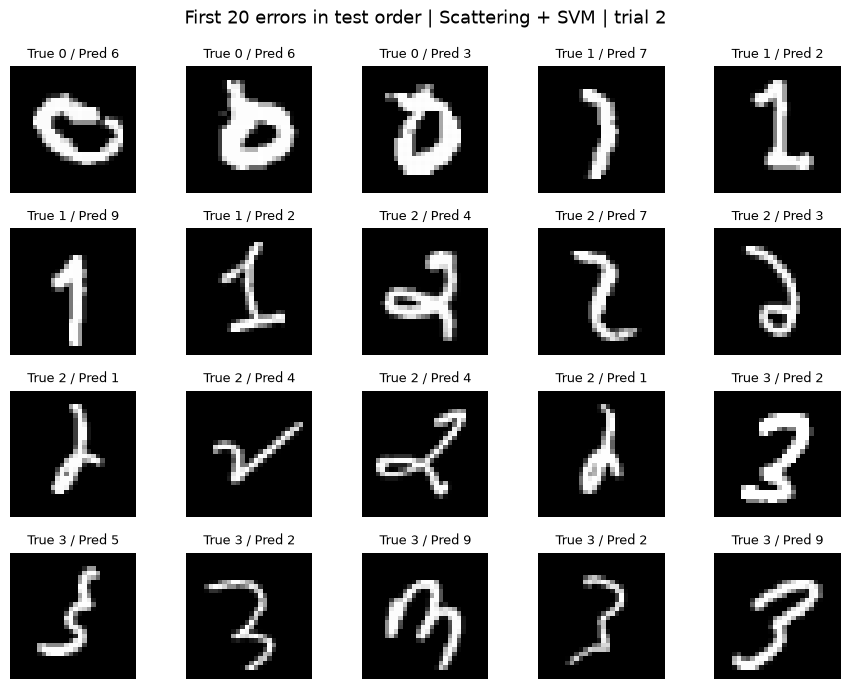

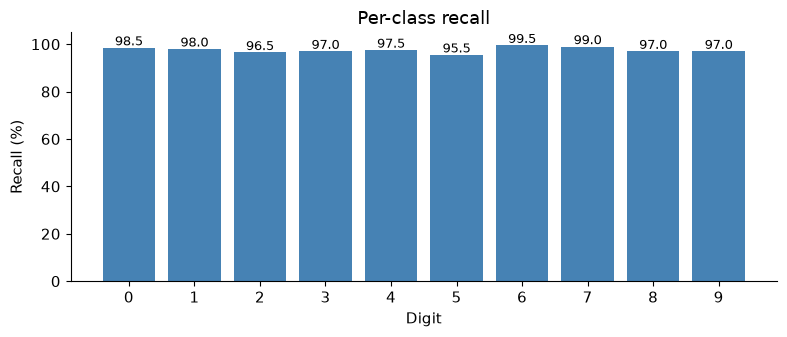

Scattering + SVM trial 2 accuracy = 0.9755


In [3]:
rows = []
for trial in [1, 2]:
    folder = output_folder("scattering", trial)
    train_indices = data["train_indices"][trial - 1]
    test_indices = data["test_indices"][trial - 1]
    X_train, y_train = features[train_indices], data["labels"][train_indices]
    X_test, y_test = features[test_indices], data["labels"][test_indices]
    fit, val = validation_indices(y_train, seed=SEED)
    np.savez(folder / "validation_indices.npz", fit=fit, validation=val,
             original_train_indices=train_indices)
    plot_training_split(y_train, fit, val, folder)
    validation_rows = []
    best_score = -1
    best_C = None
    start = time.perf_counter()
    for C in C_values:
        candidate = make_pipeline(StandardScaler(), SVC(C=C, kernel="linear", cache_size=256))
        fit_start = time.perf_counter()
        candidate.fit(X_train[fit], y_train[fit])
        validation_score = candidate.score(X_train[val], y_train[val])
        validation_rows.append({"C": C, "train_accuracy": candidate.score(X_train[fit], y_train[fit]),
                                "validation_accuracy": validation_score,
                                "fit_seconds": time.perf_counter() - fit_start})
        if validation_score > best_score:
            best_score, best_C = validation_score, C
    validation = pd.DataFrame(validation_rows)
    validation.to_csv(folder / "validation_results.csv", index=False)
    display(validation)

    # Freeze C using validation only; refit on the complete prescribed training set.
    model = make_pipeline(StandardScaler(), SVC(C=best_C, kernel="linear", cache_size=256))
    model.fit(X_train, y_train)
    train_seconds = time.perf_counter() - start
    joblib.dump(model, folder / "model.joblib")
    save_json({"trial": trial, "J": 2, "L": 8, "max_order": 2,
               "svm_implementation": "SVC (LIBSVM)", "kernel": "linear",
               "C_values": C_values, "selected_C": best_C, "best_validation_accuracy": best_score,
               "split_seed": SEED, "n_train": 2000, "validation_fraction": 0.2}, folder / "config.json")

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.semilogx(validation["C"], validation["train_accuracy"] * 100, "o-", label="Fit (1,600)")
    ax.semilogx(validation["C"], validation["validation_accuracy"] * 100, "o-", label="Validation (400)")
    ax.axvline(best_C, color="gray", linestyle="--", label="Selected C")
    ax.set(xlabel="Linear SVM C", ylabel="Accuracy (%)", title="Training-only parameter selection")
    ax.legend()
    fig.tight_layout()
    save_figure(fig, folder, "svm_validation_curve")

    start = time.perf_counter()
    predictions = model.predict(X_test)
    predict_seconds = time.perf_counter() - start
    metrics = evaluate_predictions(y_test, predictions, data["images"][test_indices], folder,
                                   "Scattering + SVM", trial, train_seconds, predict_seconds,
                                   sample_indices=test_indices)
    rows.append(metrics)

## 3. 汇总与三种方法比较
时间表中的 Scattering 预测时间仅含 SVM；部署到新图像还需要计算散射特征。准确率比较图显示 CNN 的两个增强设置，但仍属于同一个 CNN 方法。

,method,trial,n_test,accuracy,macro_f1,train_seconds,predict_seconds
0,Scattering + SVM,1,2000,0.9765,0.976526,17.401852,3.655621
1,Scattering + SVM,2,2000,0.9755,0.975497,18.454682,3.739761


,method,mean_accuracy,std_accuracy,mean_macro_f1,mean_train_seconds,mean_predict_seconds
0,Scattering + SVM,0.976,0.000707,0.976011,17.928267,3.697691


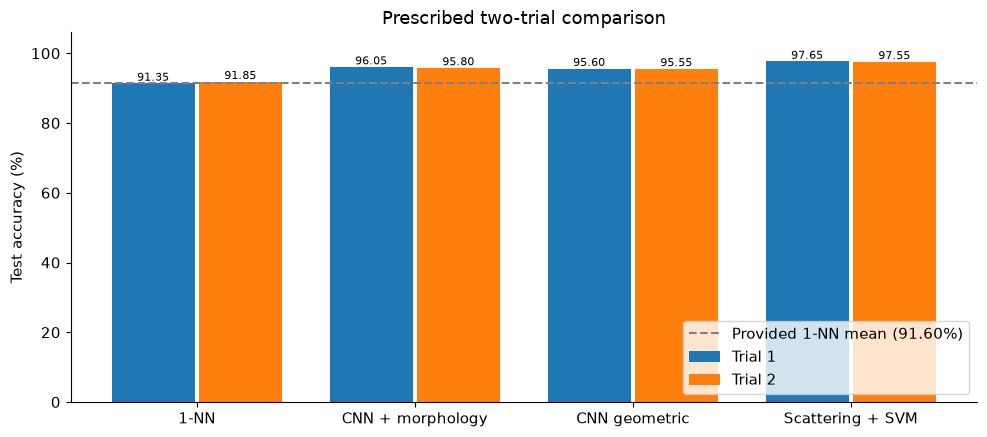

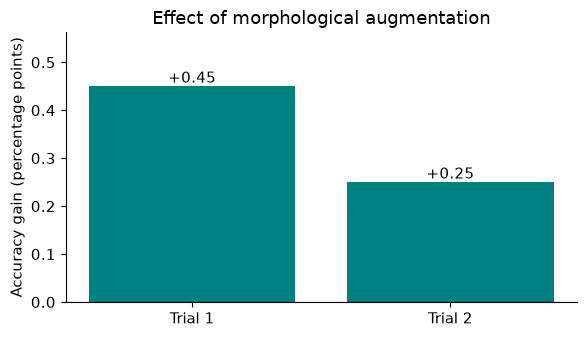

,method,mean_accuracy,std_accuracy,mean_macro_f1,mean_train_seconds,mean_predict_seconds
0,1-NN,0.91600,0.003536,0.915482,0.022998,0.132497
1,CNN + morphology,0.95925,0.001768,0.959263,46.743297,0.257345
2,CNN geometric,0.95575,0.000354,0.955727,42.834622,0.265899
3,Scattering + SVM,0.97600,0.000707,0.976011,17.928267,3.697691


In [4]:
display(pd.DataFrame(rows))
display(save_method_summary(rows, output_folder("scattering")))
display(compare_methods())

## 4. 附加挑战接口

`new_images` 必须已经正确整理为亮字黑底的 `[N,28,28]`、`float32`、`[0,1]` 数组。新的数据使用独立缓存文件，不要覆盖原始数据系数：

```python
new_features, seconds = scattering_features(new_images, ROOT / ".cache" / "challenge_scattering.npy")
model = joblib.load(output_folder("scattering", 1) / "model.joblib")
new_predictions = model.predict(new_features)
```

**参考：** Bruna & Mallat, *Invariant Scattering Convolution Networks*, https://arxiv.org/abs/1203.1513 。实现库 Kymatio: https://www.kymat.io/ 。